In [1]:
pip install pandas numpy matplotlib seaborn jupyter openpyxl scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 58.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 41.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 79.5 MB/s eta 0:00:00


# Step 1 — Load and inspect the datasets

In [37]:

# STEP 1: IMPORT LIBRARIES AND LOAD DATASETS

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

DATA_DIR = Path("/content")

bookings = pd.read_csv(DATA_DIR / "bookings.csv")
movies = pd.read_csv(DATA_DIR / "movies.csv")
cinemas = pd.read_csv(DATA_DIR / "cinemas.csv")
pricing = pd.read_csv(DATA_DIR / "pricing.csv")
calendar = pd.read_csv(DATA_DIR / "calendar.csv")

for name, data in {
    "Bookings": bookings,
    "Movies": movies,
    "Cinemas": cinemas,
    "Pricing": pricing,
    "Calendar": calendar
}.items():
    print(f"\n{name}: {data.shape}")
    print("Columns:", data.columns.tolist())
    print("Missing values:", data.isnull().sum().sum())
    print("Duplicate rows:", data.duplicated().sum())
    display(data.head(3))



Bookings: (1200, 9)
Columns: ['booking_id', 'date', 'cinema', 'screen', 'movie', 'show_time', 'seat_class', 'tickets', 'revenue']
Missing values: 0
Duplicate rows: 0


,booking_id,date,cinema,screen,movie,show_time,seat_class,tickets,revenue
0,B00001,2025-03-07,CIN01,CIN01-S1,M012,Evening,Standard,208,37440.0
1,B00002,2025-02-05,CIN04,CIN04-S4,M008,Afternoon,Standard,79,14220.0
2,B00003,2025-01-09,CIN05,CIN05-S5,M017,Night,Premium,125,31250.0



Movies: (20, 6)
Columns: ['movie', 'movie_title', 'genre', 'language', 'runtime', 'certification']
Missing values: 0
Duplicate rows: 0


,movie,movie_title,genre,language,runtime,certification
0,M001,Sky Warriors,Action,Tamil,142,UA
1,M002,Laughing Street,Comedy,Tamil,118,U
2,M003,The Last Kingdom,Drama,English,135,UA



Cinemas: (8, 4)
Columns: ['cinema', 'city', 'screen_capacity', 'screen']
Missing values: 0
Duplicate rows: 0


,cinema,city,screen_capacity,screen
0,CIN01,Chennai,220,CIN01-S1
1,CIN02,Bengaluru,200,CIN02-S2
2,CIN03,Coimbatore,180,CIN03-S3



Pricing: (9, 4)
Columns: ['seat_class', 'ticket_price', 'offer', 'discount_rate']
Missing values: 0
Duplicate rows: 0


,seat_class,ticket_price,offer,discount_rate
0,Standard,180,No Offer,0.0
1,Premium,250,No Offer,0.0
2,Recliner,380,No Offer,0.0



Calendar: (70, 4)
Columns: ['date', 'weekday', 'holiday', 'release_week']
Missing values: 0
Duplicate rows: 0


,date,weekday,holiday,release_week
0,2025-01-01,Wednesday,No,1
1,2025-01-02,Thursday,No,1
2,2025-01-03,Friday,No,1


# Step 2 — Clean and merge the data

In [38]:

# STEP 2: CLEAN AND MERGE

# Remove exact duplicates
bookings = bookings.drop_duplicates().copy()
movies = movies.drop_duplicates().copy()
cinemas = cinemas.drop_duplicates().copy()
calendar = calendar.drop_duplicates().copy()

# Parse dates
bookings["date"] = pd.to_datetime(bookings["date"], errors="coerce")
calendar["date"] = pd.to_datetime(calendar["date"], errors="coerce")

# Clean text columns
for data in [bookings, movies, cinemas, pricing, calendar]:
    for col in data.select_dtypes(include="object").columns:
        data[col] = data[col].str.strip()

# Convert numeric columns
bookings["tickets"] = pd.to_numeric(bookings["tickets"], errors="coerce")
bookings["revenue"] = pd.to_numeric(bookings["revenue"], errors="coerce")

# Remove invalid records
bookings = bookings.dropna(
    subset=["date", "cinema", "screen", "movie",
            "show_time", "seat_class", "tickets"]
)
bookings = bookings[
    (bookings["tickets"] > 0) &
    (bookings["tickets"] % 1 == 0)
].copy()

# Revenue is required for revenue analysis, but not for ticket prediction
bookings["revenue"] = bookings["revenue"].where(bookings["revenue"] >= 0)

# Merge movie information
df = bookings.merge(
    movies, on="movie", how="left", validate="many_to_one"
)

# Merge cinema data using available common identifiers
cinema_keys = ["cinema"]
if "screen" in df.columns and "screen" in cinemas.columns:
    cinema_keys = ["cinema", "screen"]

df = df.merge(
    cinemas, on=cinema_keys, how="left",
    validate="many_to_one", suffixes=("", "_cinema")
)

# Merge calendar information
calendar_columns = [
    c for c in ["date", "weekday", "holiday", "release_week"]
    if c in calendar.columns
]
calendar_for_merge = calendar[calendar_columns].drop_duplicates("date")

df = df.merge(
    calendar_for_merge, on="date", how="left",
    validate="many_to_one", suffixes=("", "_calendar")
)

# Derive date features
df["day_of_week"] = df["date"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# Fill missing predictors with explicit placeholders or medians
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna("Unknown")

for col in ["screen_capacity", "runtime", "release_week"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].fillna(df[col].median())

print("Merged dataset shape:", df.shape)
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

display(df.head())


Merged dataset shape: (1200, 21)

Missing values:


,Missing Values
booking_id,0
date,0
cinema,0
screen,0
movie,0
show_time,0
seat_class,0
tickets,0
revenue,0
movie_title,0


,booking_id,date,cinema,screen,movie,show_time,seat_class,tickets,revenue,movie_title,...,language,runtime,certification,city,screen_capacity,weekday,holiday,release_week,day_of_week,is_weekend
0,B00001,2025-03-07,CIN01,CIN01-S1,M012,Evening,Standard,208,37440.0,Street Racer,...,Telugu,138,UA,Chennai,220,Friday,No,10,4,0
1,B00002,2025-02-05,CIN04,CIN04-S4,M008,Afternoon,Standard,79,14220.0,Galaxy Run,...,English,150,UA,Madurai,160,Wednesday,No,6,2,0
2,B00003,2025-01-09,CIN05,CIN05-S5,M017,Night,Premium,125,31250.0,Tiny Heroes,...,Tamil,98,U,Hyderabad,210,Thursday,No,2,3,0
3,B00004,2025-03-10,CIN07,CIN07-S7,M009,Morning,Recliner,82,28044.0,Hidden Truth,...,Tamil,121,UA,Pune,190,Monday,No,10,0,0
4,B00005,2025-02-21,CIN04,CIN04-S4,M008,Evening,Recliner,154,49742.0,Galaxy Run,...,English,150,UA,Madurai,160,Friday,No,8,4,0


# Step 3 — Exploratory data analysis

,Total Revenue
genre,
Drama,6718164.0
Action,6139550.5
Comedy,5675675.5
Thriller,4862503.5
Adventure,3263168.5
Animation,2609075.5
Romance,1751465.5
Historical,1675646.5
Sci-Fi,1644586.0


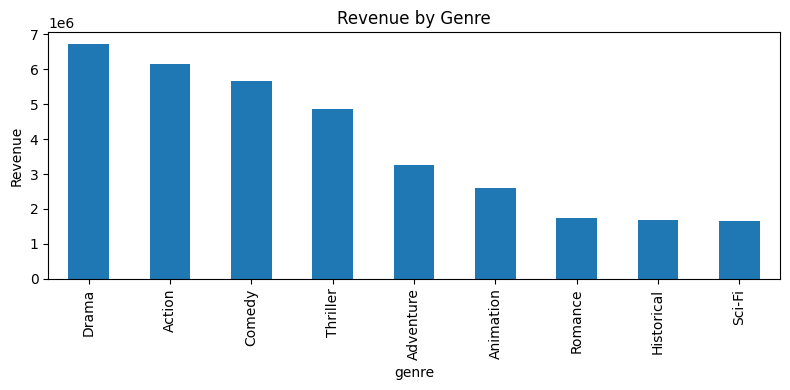

,Average Tickets
show_time,
Evening,172.572939
Night,150.498069
Afternoon,117.540984
Morning,76.156250


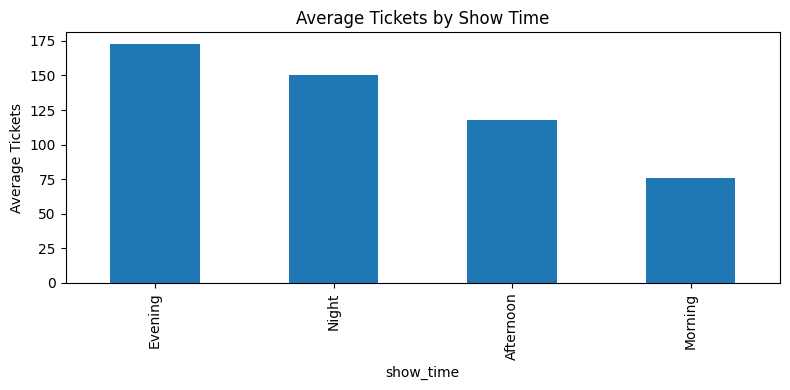

,average_tickets,total_tickets
day_type,,
Weekday,133.242389,113789
Weekend,151.895954,52556


,Total Revenue
cinema,
CIN08,5592434.5
CIN01,4570832.5
CIN05,4529258.0
CIN02,4465360.0
CIN03,4428161.0
CIN07,3805206.0
CIN04,3597498.5
CIN06,3351085.0


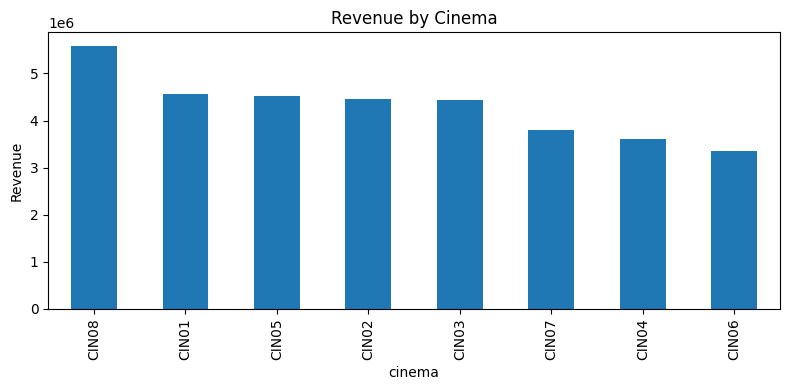

In [39]:

# STEP 3: EDA CHARTS

# Revenue by genre
if {"genre", "revenue"}.issubset(df.columns):
    genre_summary = df.groupby("genre")["revenue"].sum().sort_values(ascending=False)
    display(genre_summary.to_frame("Total Revenue"))
    genre_summary.plot(kind="bar", figsize=(8, 4), title="Revenue by Genre")
    plt.ylabel("Revenue")
    plt.tight_layout()
    plt.show()

# Tickets by show time
show_summary = df.groupby("show_time")["tickets"].mean().sort_values(ascending=False)
display(show_summary.to_frame("Average Tickets"))
show_summary.plot(kind="bar", figsize=(8, 4), title="Average Tickets by Show Time")
plt.ylabel("Average Tickets")
plt.tight_layout()
plt.show()

# Weekend vs weekday
df["day_type"] = np.where(df["is_weekend"] == 1, "Weekend", "Weekday")
day_summary = df.groupby("day_type").agg(
    average_tickets=("tickets", "mean"),
    total_tickets=("tickets", "sum")
)
display(day_summary)

# Revenue by cinema
if "revenue" in df.columns:
    cinema_summary = df.groupby("cinema")["revenue"].sum().sort_values(ascending=False)
    display(cinema_summary.to_frame("Total Revenue"))
    cinema_summary.plot(kind="bar", figsize=(8, 4), title="Revenue by Cinema")
    plt.ylabel("Revenue")
    plt.tight_layout()
    plt.show()


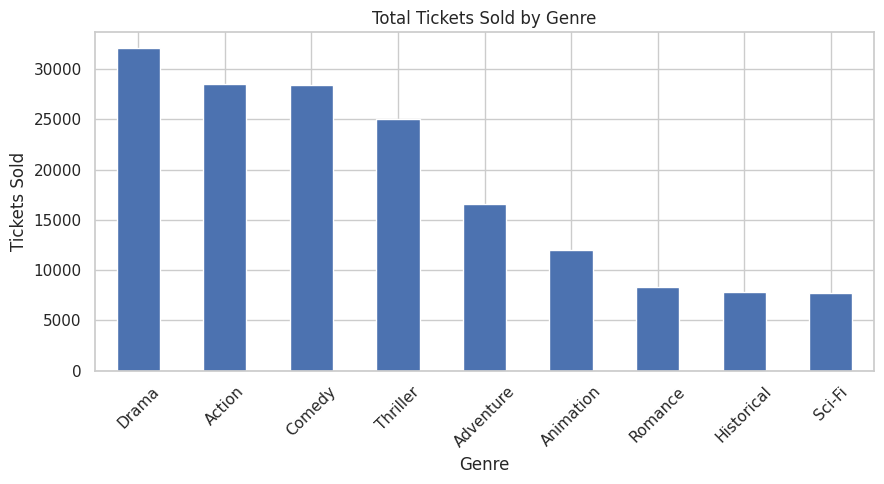

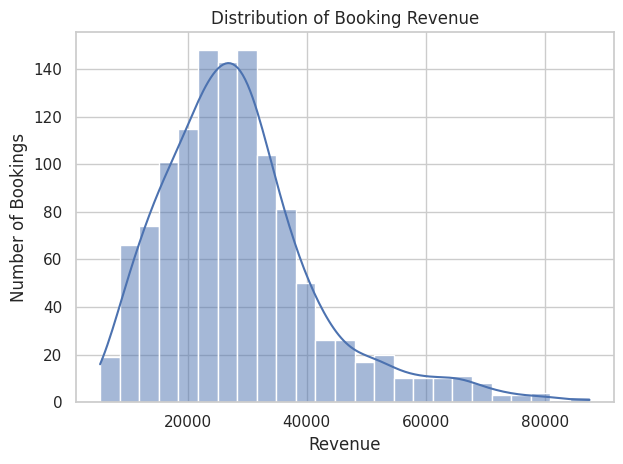

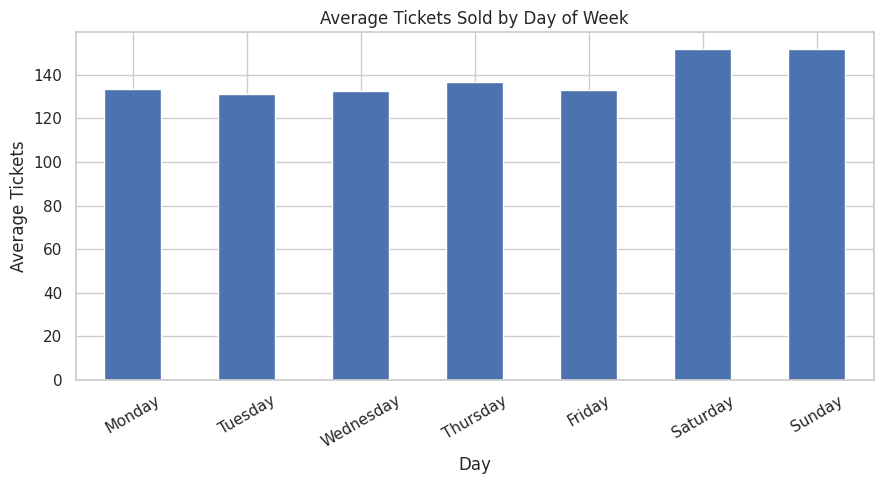

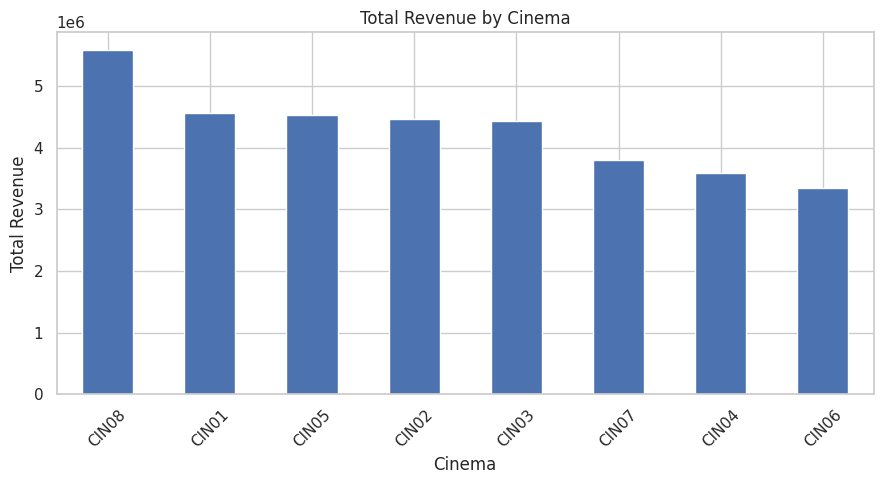

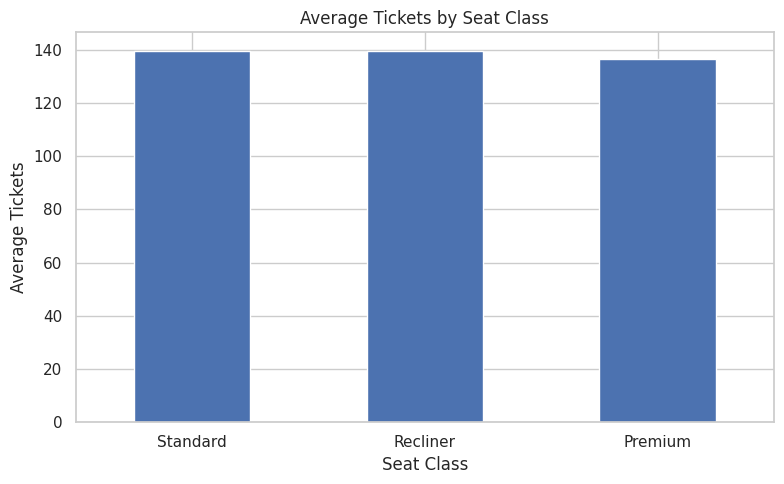

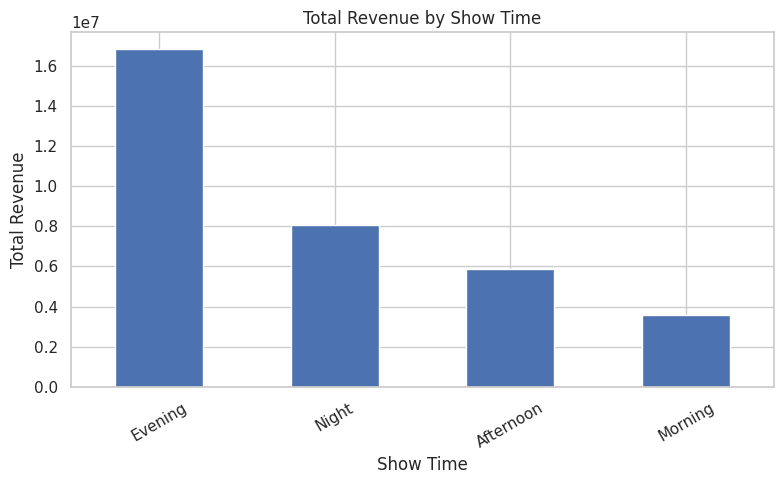

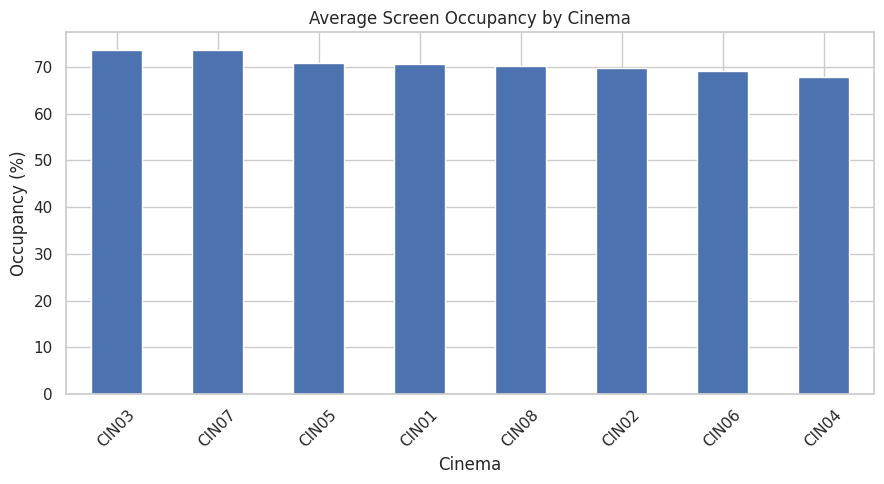

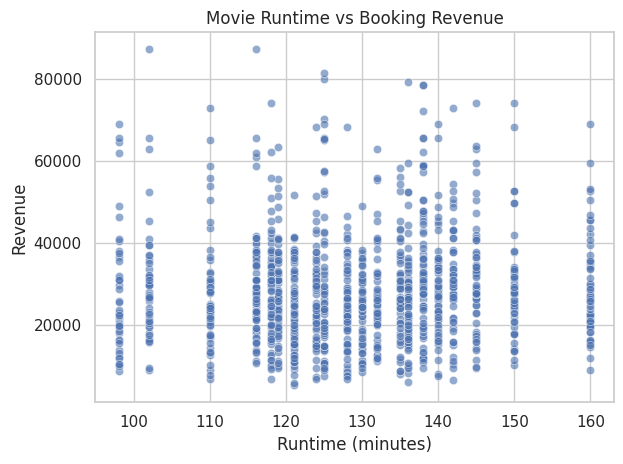

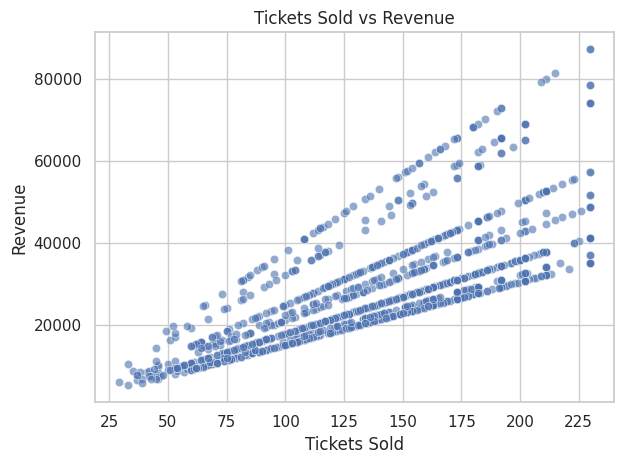

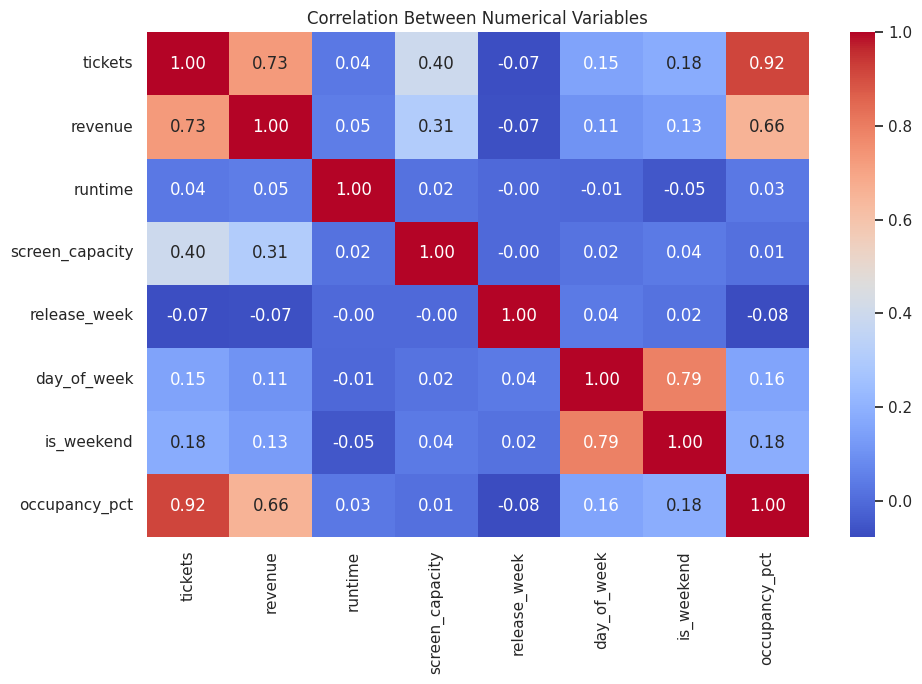

EDA COMPLETED: Additional charts generated.


In [40]:

# ============================================================
# CH29 - CINEMA REVENUE INSIGHT
# ADDITIONAL EXPLORATORY DATA ANALYSIS (EDA)
# Run after Step 3, when df is available
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Convert important columns to numeric when available
for col in ["tickets", "revenue", "screen_capacity", "runtime"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Create useful derived columns
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["month"] = df["date"].dt.month_name()
    df["day_name"] = df["date"].dt.day_name()

if "screen_capacity" in df.columns:
    df["occupancy_pct"] = (
        df["tickets"] / df["screen_capacity"] * 100
    )

# ------------------------------------------------------------
# CHART 3: TICKET SALES BY MOVIE GENRE
# ------------------------------------------------------------
if "genre" in df.columns:
    data = df.groupby("genre")["tickets"].sum().sort_values(ascending=False)
    data.plot(kind="bar", figsize=(9, 5))
    plt.title("Total Tickets Sold by Genre")
    plt.xlabel("Genre")
    plt.ylabel("Tickets Sold")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# CHART 4: REVENUE DISTRIBUTION
# ------------------------------------------------------------
if "revenue" in df.columns:
    sns.histplot(df["revenue"].dropna(), bins=25, kde=True)
    plt.title("Distribution of Booking Revenue")
    plt.xlabel("Revenue")
    plt.ylabel("Number of Bookings")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# CHART 5: TICKET SALES BY WEEKDAY
# ------------------------------------------------------------
if "day_name" in df.columns:
    day_order = [
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ]
    data = df.groupby("day_name")["tickets"].mean().reindex(day_order)
    data.plot(kind="bar", figsize=(9, 5))
    plt.title("Average Tickets Sold by Day of Week")
    plt.xlabel("Day")
    plt.ylabel("Average Tickets")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# CHART 6: REVENUE BY CINEMA
# ------------------------------------------------------------
if {"cinema", "revenue"}.issubset(df.columns):
    data = df.groupby("cinema")["revenue"].sum().sort_values(ascending=False)
    data.plot(kind="bar", figsize=(9, 5))
    plt.title("Total Revenue by Cinema")
    plt.xlabel("Cinema")
    plt.ylabel("Total Revenue")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# CHART 7: TICKET SALES BY SEAT CLASS
# ------------------------------------------------------------
if "seat_class" in df.columns:
    data = df.groupby("seat_class")["tickets"].mean().sort_values(ascending=False)
    data.plot(kind="bar", figsize=(8, 5))
    plt.title("Average Tickets by Seat Class")
    plt.xlabel("Seat Class")
    plt.ylabel("Average Tickets")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# CHART 8: REVENUE BY SHOW TIME
# ------------------------------------------------------------
if {"show_time", "revenue"}.issubset(df.columns):
    data = df.groupby("show_time")["revenue"].sum().sort_values(ascending=False)
    data.plot(kind="bar", figsize=(8, 5))
    plt.title("Total Revenue by Show Time")
    plt.xlabel("Show Time")
    plt.ylabel("Total Revenue")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# CHART 9: AVERAGE OCCUPANCY BY CINEMA
# ------------------------------------------------------------
if {"cinema", "occupancy_pct"}.issubset(df.columns):
    data = df.groupby("cinema")["occupancy_pct"].mean().sort_values(ascending=False)
    data.plot(kind="bar", figsize=(9, 5))
    plt.title("Average Screen Occupancy by Cinema")
    plt.xlabel("Cinema")
    plt.ylabel("Occupancy (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# CHART 10: RUNTIME VS REVENUE
# ------------------------------------------------------------
if {"runtime", "revenue"}.issubset(df.columns):
    sns.scatterplot(data=df, x="runtime", y="revenue", alpha=0.6)
    plt.title("Movie Runtime vs Booking Revenue")
    plt.xlabel("Runtime (minutes)")
    plt.ylabel("Revenue")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# CHART 11: TICKETS VS REVENUE
# ------------------------------------------------------------
sns.scatterplot(data=df, x="tickets", y="revenue", alpha=0.6)
plt.title("Tickets Sold vs Revenue")
plt.xlabel("Tickets Sold")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# CHART 12: CORRELATION HEATMAP
# ------------------------------------------------------------
numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Correlation Between Numerical Variables")
    plt.tight_layout()
    plt.show()

print("EDA COMPLETED: Additional charts generated.")


# Step 4 — Prepare the target and features

In [41]:

# STEP 4: PREPARE FEATURES AND TARGET

from sklearn.model_selection import train_test_split

# Use predictors that are available in the merged dataset
candidate_features = [
    "cinema", "show_time", "seat_class", "movie",
    "genre", "language", "certification", "city",
    "screen_capacity", "runtime", "weekday",
    "holiday", "release_week", "is_weekend", "day_of_week"
]

features = [c for c in candidate_features if c in df.columns]
target = "tickets"

if len(features) == 0:
    raise ValueError("No predictor features were found.")

model_df = df[features + [target]].copy()
model_df[target] = pd.to_numeric(model_df[target], errors="coerce")
model_df = model_df.dropna(subset=[target])
model_df = model_df[model_df[target] > 0].copy()

# Make categorical values consistent
categorical_features = model_df[features].select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = [
    c for c in features if c not in categorical_features
]

# Train/validation/test split: 60% / 20% / 20%
train_df, temp_df = train_test_split(
    model_df, test_size=0.40, random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42
)

# Learn category boundaries only from training tickets
low_threshold = train_df[target].quantile(1/3)
high_threshold = train_df[target].quantile(2/3)

def make_demand_class(values):
    values = np.asarray(values)
    return np.where(
        values <= low_threshold, "Low",
        np.where(values <= high_threshold, "Medium", "High")
    )

y_train = make_demand_class(train_df[target])
y_val = make_demand_class(val_df[target])
y_test = make_demand_class(test_df[target])

X_train = train_df[features].copy()
X_val = val_df[features].copy()
X_test = test_df[features].copy()

print("Features:", features)
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))
print(f"Low demand: tickets <= {low_threshold:.1f}")
print(f"Medium demand: {low_threshold:.1f} to {high_threshold:.1f}")
print(f"High demand: tickets > {high_threshold:.1f}")


Features: ['cinema', 'show_time', 'seat_class', 'movie', 'genre', 'language', 'certification', 'city', 'screen_capacity', 'runtime', 'weekday', 'holiday', 'release_week', 'is_weekend', 'day_of_week']
Training rows: 720
Validation rows: 240
Testing rows: 240
Low demand: tickets <= 119.0
Medium demand: 119.0 to 160.3
High demand: tickets > 160.3


# Step 5 — Train and compare models

In [42]:

# STEP 5: COMPARE CLASSIFICATION MODELS

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score

def build_preprocessor():
    return ColumnTransformer([
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features),
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numerical_features)
    ])

# These models can use the same preprocessing pipeline
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
}

# HistGradientBoosting needs dense input, so use a separate
# dense preprocessing pipeline for it.
def build_dense_preprocessor():
    return ColumnTransformer([
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore", sparse_output=False
            ))
        ]), categorical_features),
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numerical_features)
    ])

trained_models = {}
validation_results = []

for name, estimator in models.items():
    prep = (
        build_dense_preprocessor()
        if name == "Hist Gradient Boosting"
        else build_preprocessor()
    )

    pipeline = Pipeline([
        ("preprocessor", prep),
        ("classifier", estimator)
    ])

    pipeline.fit(X_train, y_train)
    val_pred = pipeline.predict(X_val)

    trained_models[name] = pipeline

    validation_results.append({
        "Model": name,
        "Validation Accuracy (%)":
            accuracy_score(y_val, val_pred) * 100,
        "Validation Macro F1 (%)":
            f1_score(y_val, val_pred, average="macro") * 100,
        "Validation Weighted F1 (%)":
            f1_score(y_val, val_pred, average="weighted") * 100
    })

validation_table = pd.DataFrame(validation_results).sort_values(
    "Validation Macro F1 (%)", ascending=False
)

display(validation_table.round(2))

best_name = validation_table.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Selected model:", best_name)
print("Selection criterion: highest validation macro F1-score")


,Model,Validation Accuracy (%),Validation Macro F1 (%),Validation Weighted F1 (%)
2,Hist Gradient Boosting,82.08,80.93,82.52
0,Random Forest,79.17,77.42,79.50
1,Extra Trees,77.92,76.13,78.30


Selected model: Hist Gradient Boosting
Selection criterion: highest validation macro F1-score


# Step 6 — Final evaluation: accuracy, precision, recall, F1 and confusion matrix

FINAL TEST SET RESULTS
Selected model: Hist Gradient Boosting
Accuracy: 74.17%
Macro Precision: 73.94%
Macro Recall: 75.01%
Macro F1-score: 74.22%
Weighted Precision: 73.66%
Weighted Recall: 74.17%
Weighted F1-score: 73.66%

Classification report:
              precision    recall  f1-score   support

         Low       0.78      0.89      0.83        70
      Medium       0.68      0.58      0.62        85
        High       0.75      0.79      0.77        85

    accuracy                           0.74       240
   macro avg       0.74      0.75      0.74       240
weighted avg       0.74      0.74      0.74       240



,Predicted Low,Predicted Medium,Predicted High
Actual Low,62,7,1
Actual Medium,15,49,21
Actual High,2,16,67


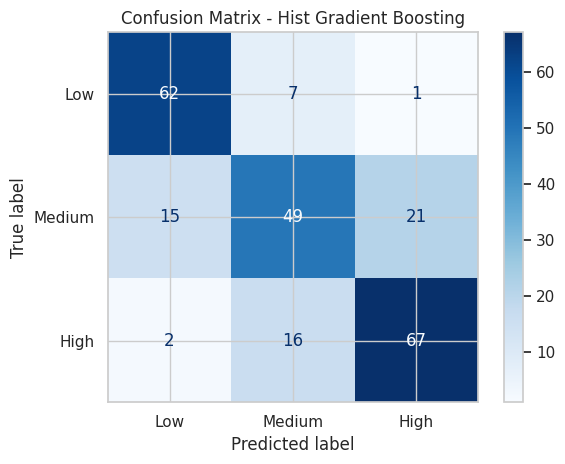

In [43]:

# STEP 6: FINAL CLASSIFICATION EVALUATION

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score
)

labels = ["Low", "Medium", "High"]

test_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, test_pred)
precision_macro = precision_score(
    y_test, test_pred, labels=labels,
    average="macro", zero_division=0
)
recall_macro = recall_score(
    y_test, test_pred, labels=labels,
    average="macro", zero_division=0
)
f1_macro = f1_score(
    y_test, test_pred, labels=labels,
    average="macro", zero_division=0
)
precision_weighted = precision_score(
    y_test, test_pred, labels=labels,
    average="weighted", zero_division=0
)
recall_weighted = recall_score(
    y_test, test_pred, labels=labels,
    average="weighted", zero_division=0
)
f1_weighted = f1_score(
    y_test, test_pred, labels=labels,
    average="weighted", zero_division=0
)

print("=" * 55)
print("FINAL TEST SET RESULTS")
print("=" * 55)
print("Selected model:", best_name)
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Macro Precision: {precision_macro * 100:.2f}%")
print(f"Macro Recall: {recall_macro * 100:.2f}%")
print(f"Macro F1-score: {f1_macro * 100:.2f}%")
print(f"Weighted Precision: {precision_weighted * 100:.2f}%")
print(f"Weighted Recall: {recall_weighted * 100:.2f}%")
print(f"Weighted F1-score: {f1_weighted * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test, test_pred, labels=labels, zero_division=0
))

cm = confusion_matrix(y_test, test_pred, labels=labels)
display(pd.DataFrame(
    cm,
    index=[f"Actual {x}" for x in labels],
    columns=[f"Predicted {x}" for x in labels]
))

ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=labels
).plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()


# Step 7 — Evaluate actual ticket-count predictions

,Model,Validation MAE,Validation RMSE,Validation R2
0,Random Forest Regressor,15.121,19.202,0.847
1,Extra Trees Regressor,16.549,21.463,0.809



FINAL TICKET-COUNT REGRESSION RESULTS
Selected model: Random Forest Regressor
MAE: 16.94 tickets
RMSE: 22.16 tickets
R² score: 0.7656


,Actual Tickets,Predicted Tickets,Absolute Error
0,144,161.2,17.2
1,192,176.5,15.5
2,120,130.6,10.6
3,83,88.8,5.8
4,75,72.4,2.6
5,42,69.3,27.3
6,146,163.7,17.7
7,178,155.0,23.0
8,169,184.7,15.7
9,127,159.5,32.5


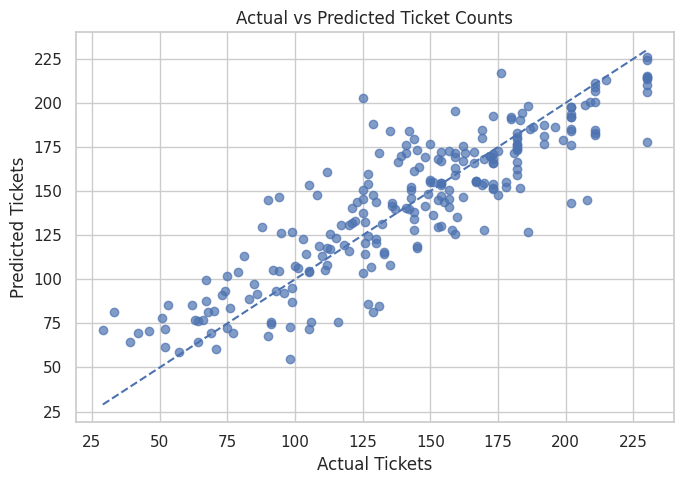

In [44]:

# STEP 7: REGRESSION METRICS FOR TICKET COUNTS

from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

regression_models = {
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    ),
    "Extra Trees Regressor": ExtraTreesRegressor(
        n_estimators=300, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    )
}

regression_pipelines = {}
regression_validation = []

for name, estimator in regression_models.items():
    pipe = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("regressor", estimator)
    ])

    pipe.fit(X_train, train_df[target])
    val_prediction = pipe.predict(X_val)

    regression_pipelines[name] = pipe
    regression_validation.append({
        "Model": name,
        "Validation MAE": mean_absolute_error(
            val_df[target], val_prediction
        ),
        "Validation RMSE": np.sqrt(mean_squared_error(
            val_df[target], val_prediction
        )),
        "Validation R2": r2_score(
            val_df[target], val_prediction
        )
    })

regression_table = pd.DataFrame(regression_validation).sort_values(
    "Validation MAE"
)
display(regression_table.round(3))

best_regression_name = regression_table.iloc[0]["Model"]
ticket_model = regression_pipelines[best_regression_name]

# Evaluate once on the held-out test set
ticket_pred = ticket_model.predict(X_test)

mae = mean_absolute_error(test_df[target], ticket_pred)
rmse = np.sqrt(mean_squared_error(test_df[target], ticket_pred))
r2 = r2_score(test_df[target], ticket_pred)

print("\nFINAL TICKET-COUNT REGRESSION RESULTS")
print("Selected model:", best_regression_name)
print(f"MAE: {mae:.2f} tickets")
print(f"RMSE: {rmse:.2f} tickets")
print(f"R² score: {r2:.4f}")

ticket_results = pd.DataFrame({
    "Actual Tickets": test_df[target].to_numpy(),
    "Predicted Tickets": np.round(ticket_pred, 1)
})
ticket_results["Absolute Error"] = np.abs(
    ticket_results["Actual Tickets"] -
    ticket_results["Predicted Tickets"]
).round(1)

display(ticket_results.head(20))

plt.figure(figsize=(7, 5))
plt.scatter(test_df[target], ticket_pred, alpha=0.7)
low = min(test_df[target].min(), ticket_pred.min())
high = max(test_df[target].max(), ticket_pred.max())
plt.plot([low, high], [low, high], "--")
plt.xlabel("Actual Tickets")
plt.ylabel("Predicted Tickets")
plt.title("Actual vs Predicted Ticket Counts")
plt.tight_layout()
plt.show()


# Step 8 — Interactive prediction prototype

In [46]:

# STEP 8: INTERACTIVE TICKET PREDICTION

import ipywidgets as widgets
from IPython.display import display, clear_output

controls = {}

for col in categorical_features:
    options = sorted(
        X_train[col].dropna().astype(str).unique().tolist()
    )
    controls[col] = widgets.Dropdown(
        options=options,
        value=options[0],
        description=col,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="450px")
    )

for col in numerical_features:
    vals = pd.to_numeric(X_train[col], errors="coerce").dropna()
    low, high = float(vals.min()), float(vals.max())

    controls[col] = widgets.FloatSlider(
        value=float(vals.median()),
        min=low,
        max=high if high > low else low + 1,
        step=1.0 if high - low >= 1 else 0.1,
        description=col,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="450px")
    )

button = widgets.Button(
    description="Predict Tickets",
    button_style="success"
)
output = widgets.Output()

def run_prediction(_):
    with output:
        clear_output(wait=True)

        row = {col: widget.value for col, widget in controls.items()}
        input_df = pd.DataFrame([row], columns=features)

        prediction = max(0, float(ticket_model.predict(input_df)[0]))

        print("CINEMA REVENUE INSIGHT")
        print("----------------------")
        print("Selected model:", best_regression_name)
        print(f"Estimated tickets sold: {round(prediction)}")
        print(f"Raw prediction: {prediction:.2f}")


button.on_click(run_prediction)

display(widgets.VBox(
    list(controls.values()) + [button, output]
))


# Step 9 — Save your project results

In [47]:

# STEP 9: EXPORT RESULTS

from pathlib import Path

out_dir = Path("/content/CH29_output")
out_dir.mkdir(parents=True, exist_ok=True)

classification_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Macro Precision (%)",
        "Macro Recall (%)",
        "Macro F1 (%)",
        "Weighted Precision (%)",
        "Weighted Recall (%)",
        "Weighted F1 (%)"
    ],
    "Value": [
        accuracy * 100,
        precision_macro * 100,
        recall_macro * 100,
        f1_macro * 100,
        precision_weighted * 100,
        recall_weighted * 100,
        f1_weighted * 100
    ]
})

regression_metrics = pd.DataFrame({
    "Metric": ["MAE (tickets)", "RMSE (tickets)", "R2"],
    "Value": [mae, rmse, r2]
})

classification_metrics.to_csv(
    out_dir / "classification_metrics.csv", index=False
)
regression_metrics.to_csv(
    out_dir / "regression_metrics.csv", index=False
)
ticket_results.to_csv(
    out_dir / "ticket_predictions.csv", index=False
)
df.to_csv(
    out_dir / "cinema_cleaned_merged.csv", index=False
)

with pd.ExcelWriter(
    out_dir / "CH29_Final_Results.xlsx", engine="openpyxl"
) as writer:
    classification_metrics.to_excel(
        writer, sheet_name="Classification_Metrics", index=False
    )
    regression_metrics.to_excel(
        writer, sheet_name="Regression_Metrics", index=False
    )
    validation_table.to_excel(
        writer, sheet_name="Classifier_Comparison", index=False
    )
    regression_table.to_excel(
        writer, sheet_name="Regressor_Comparison", index=False
    )
    ticket_results.to_excel(
        writer, sheet_name="Ticket_Predictions", index=False
    )
    df.to_excel(
        writer, sheet_name="Cleaned_Data", index=False
    )

print("All outputs saved to:", out_dir)
print("Excel workbook:", out_dir / "CH29_Final_Results.xlsx")

from google.colab import files
files.download(str(out_dir / "CH29_Final_Results.xlsx"))


All outputs saved to: /content/CH29_output
Excel workbook: /content/CH29_output/CH29_Final_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>